# Proyecto 2 — Modelo A (v2): detección clásica + enlace por asignación lineal

**CC3084 Data Science · UVG · Semestre II 2026**
Isabella Obando · Anthony Lou · Fabian Prado · Fernando Mendoza

Línea base **sin entrenamiento** para *Biohub — Cell Tracking During Development*. Es la línea base que
propone la investigación del grupo (sección 3.2): seguimiento por detección, con un filtro clásico para
localizar núcleos y asignación lineal (algoritmo húngaro) para enlazarlos entre instantes.

| Etapa | Método | Parámetros tomados del análisis exploratorio |
|---|---|---|
| Normalización | cuantiles p1 – p99.9 **por volumen e instante** | la intensidad varía ~3× entre embriones y crece con el tiempo (EDA 5.10.b) |
| Detección | diferencia de gaussianas (DoG) 3D + máximos locales | filtros en **micras**, no en vóxeles, por la anisotropía 4:1 (EDA 4.4) |
| Enlace | asignación lineal t → t+1 con radio máximo | radio = p99 del desplazamiento, **8.4 µm** (EDA 5.1) |
| Deriva | desplazamiento medio del instante, restado antes de enlazar | deriva de −0.5 µm/frame en Z (EDA 5.6) |
| Divisiones | heurística: segunda hija cercana a una madre ya enlazada | 54% de las aristas de división son atípicas (EDA 5.7); pesan solo 0.1 en la métrica |

**Cambios de la v2.** La v1 (σ ≤ 2.5 µm) obtuvo un Jaccard de aristas ajustado de **0.745** en
validación, pero el mejor σ quedó en el borde de la grilla, y en la inspección visual los núcleos
grandes recibían dos detecciones. La v2:

- prueba σ de 2.5 a 4.0 µm;
- ajusta la **separación mínima entre centros** con supresión de no máximos sobre las detecciones ya
  calculadas, sin releer imágenes;
- agrega un **margen de borde** para descartar núcleos cortados por el límite del volumen;
- parte de los parámetros validados en la v1.

**Cómo se usa.** Al correrlo de forma interactiva, el notebook (1) valida y ajusta los parámetros en
muestras de `train/` con la métrica de la competencia y (2) genera `submission.csv` para `test/`.
Cuando Kaggle lo vuelve a ejecutar sobre el conjunto de prueba oculto (*rerun*), la validación se
salta y se usan los parámetros de `PARAMS`. **Después de validar, copiar los mejores parámetros a
`PARAMS`** y guardar una versión nueva antes de enviar.

No necesita GPU ni Internet: lee los archivos Zarr con un lector propio, para cumplir la regla de
*Internet: Off* al enviar.

In [1]:
import os, io, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from joblib import Parallel, delayed

COMPETITION = "biohub-cell-tracking-during-development"
ES_RERUN = bool(os.environ.get("KAGGLE_IS_COMPETITION_RERUN"))
VALIDAR = not ES_RERUN
N_JOBS = os.cpu_count() or 1


def encontrar_datos(raiz=Path("/kaggle/input")):
    """Carpeta de la competencia: la que contiene test/ (y train/) con volúmenes .zarr."""
    if os.environ.get("BIOHUB_DATA"):
        return Path(os.environ["BIOHUB_DATA"])
    candidatos = [raiz / "competitions" / COMPETITION, raiz / COMPETITION]
    for prof in range(1, 5):                       # test/ a 1 – 4 niveles de profundidad
        candidatos += [p.parent for p in sorted(raiz.glob("/".join(["*"] * prof)))
                       if p.name == "test" and p.is_dir()]
    for c in candidatos:
        if (c / "test").is_dir() and any((c / "test").glob("*.zarr")):
            return c
    contenido = sorted(str(p.relative_to(raiz)) for p in raiz.glob("*/*")) if raiz.exists() else []
    raise FileNotFoundError(
        "No se encontró la competencia en /kaggle/input. En el panel derecho, sección 'Input', "
        "agregar la competencia: + Add Input -> Competitions -> 'Biohub - Cell Tracking During Development'.\n"
        f"Contenido actual de {raiz} (2 niveles): {contenido[:30] or 'vacío'}")


DATA_DIR = encontrar_datos()
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
SALIDA = Path(os.environ.get("BIOHUB_SALIDA", "/kaggle/working"))
VOXEL_UM = np.array([1.625, 0.40625, 0.40625])     # (Z, Y, X) micras por vóxel

print(f"Datos: {DATA_DIR} | rerun: {ES_RERUN} | CPUs: {N_JOBS}")

Datos: /kaggle/input/competitions/biohub-cell-tracking-during-development | rerun: False | CPUs: 4


## Parámetros

Los valores por defecto salen del análisis exploratorio. `umbral` (cuánta respuesta debe tener un
máximo para contarlo como núcleo), `deriva`, `radio_um` y `divisiones` se ajustan en la validación.

In [2]:
PARAMS = dict(
    reduccion_xy=2,        # promedio 2x2 en XY: vóxel de 1.625 x 0.81 x 0.81 um (4x más rápido)
    sigma_um=2.5,          # escala del núcleo (v1: mejor de 1.5 / 2.0 / 2.5)
    k_dog=1.6,             # razón entre las dos gaussianas de la DoG (aproxima un LoG)
    dist_min_um=3.0,       # separación mínima entre dos centros (supresión de no máximos)
    borde_um=0.0,          # descartar detecciones a menos de esta distancia del borde del volumen
    umbral=0.01,           # respuesta DoG mínima, en unidades de intensidad normalizada
    radio_um=8.4,          # radio máximo de enlace: p99 del desplazamiento (EDA 5.1)
    deriva="dos_pasos",    # "ninguna" | "dos_pasos": restar el desplazamiento mediano del instante
    divisiones=False,      # agregar una segunda hija cuando una detección nueva aparece junto a una madre
    radio_div_um=8.0,      # distancia máxima madre -> segunda hija
)

# La detección siempre busca máximos con esta separación (la menor de la grilla); la separación
# final se aplica después con supresión de no máximos, igual en validación y en el envío.
DIST_MIN_DET = 2.0


## Lectura de los datos sin la librería `zarr`

Al enviar, Kaggle exige *Internet: Off*, así que no se puede instalar `zarr>=3`. Este lector mínimo
interpreta el `zarr.json` de cada arreglo y descomprime los fragmentos con `numcodecs`, `blosc2` o
`zstandard`, según lo que haya disponible. Cada instante de la imagen es un fragmento `(1, Z, Y, X)`.

In [3]:
import io, json
from pathlib import Path
import numpy as np


def _blosc(b):
    try:
        import numcodecs
        return numcodecs.Blosc().decode(b)
    except ImportError:
        pass
    try:
        import blosc2
        return blosc2.decompress(b)
    except ImportError:
        import blosc
        return blosc.decompress(b)


def _zstd(b):
    try:
        import numcodecs
        return numcodecs.Zstd().decode(b)
    except ImportError:
        import zstandard
        return zstandard.ZstdDecompressor().stream_reader(io.BytesIO(b)).read()


def _gzip(b):
    import gzip
    return gzip.decompress(b)


DECODIFICADORES = {"blosc": _blosc, "zstd": _zstd, "gzip": _gzip, "crc32c": lambda b: bytes(b)[:-4]}


class ArregloZarr:
    """Lector mínimo de arreglos Zarr v3 (solo lectura, sin depender de la librería zarr)."""

    def __init__(self, ruta):
        self.ruta = Path(ruta)
        m = json.loads((self.ruta / "zarr.json").read_text())
        assert m.get("node_type") == "array", f"{ruta} no es un arreglo"
        self.shape = tuple(m["shape"])
        self.chunks = tuple(m["chunk_grid"]["configuration"]["chunk_shape"])
        self.fill = m.get("fill_value") or 0
        enc = m.get("chunk_key_encoding", {"name": "default"})
        self.sep = enc.get("configuration", {}).get("separator", "/" if enc["name"] == "default" else ".")
        self.prefijo = ["c"] if enc["name"] == "default" else []
        endian = "<"
        self.codecs = []
        for c in m["codecs"]:
            n = c["name"]
            if n == "bytes":
                endian = "<" if c.get("configuration", {}).get("endian", "little") == "little" else ">"
            elif n in DECODIFICADORES:
                self.codecs.append(n)
            else:
                raise NotImplementedError(f"códec no soportado: {n}")
        self.dtype = np.dtype(m["data_type"]).newbyteorder(endian)

    def _chunk(self, idx):
        f = self.ruta / self.sep.join(self.prefijo + [str(i) for i in idx])
        if not f.exists():
            return np.full(self.chunks, self.fill, dtype=self.dtype)
        b = f.read_bytes()
        for n in reversed(self.codecs):
            b = DECODIFICADORES[n](b)
        return np.frombuffer(b, dtype=self.dtype).reshape(self.chunks)

    def leer(self):
        """Arreglo completo."""
        grid = [range(-(-s // c)) for s, c in zip(self.shape, self.chunks)]
        out = np.empty(self.shape, dtype=self.dtype.newbyteorder("="))
        for idx in np.ndindex(*[len(g) for g in grid]):
            sl = tuple(slice(i * c, min((i + 1) * c, s)) for i, c, s in zip(idx, self.chunks, self.shape))
            out[sl] = self._chunk(idx)[tuple(slice(0, x.stop - x.start) for x in sl)]
        return out

    def instante(self, t):
        """Volumen (Z, Y, X) del instante t, asumiendo chunks de un instante en el eje 0."""
        assert self.chunks[0] == 1 and self.chunks[1:] == self.shape[1:], "se esperan chunks (1, Z, Y, X)"
        return self._chunk((t, 0, 0, 0))[0].astype(self.dtype.newbyteorder("="))



def leer_grafo(geff):
    """Grafo de referencia .geff -> (DataFrame de nodos, arreglo de aristas, nodos estimados)."""
    geff = Path(geff)
    ids = ArregloZarr(geff / "nodes" / "ids").leer()
    nodos = pd.DataFrame({"node_id": ids.astype(np.int64)})
    for c in "tzyx":
        nodos[c] = ArregloZarr(geff / "nodes" / "props" / c / "values").leer().astype(float)
    aristas = ArregloZarr(geff / "edges" / "ids").leer().astype(np.int64).reshape(-1, 2)
    attrs = json.loads((geff / "zarr.json").read_text()).get("attributes", {})

    def buscar(d, k):
        if isinstance(d, dict):
            if k in d:
                return d[k]
            for v in d.values():
                r = buscar(v, k)
                if r is not None:
                    return r
        return None

    return nodos, aristas, buscar(attrs, "estimated_number_of_nodes")

## Detección

Para cada instante:

1. Se normaliza la intensidad con los cuantiles p1 y p99.9 **del propio volumen**.
2. Se promedian bloques de 2×2 en XY. Así el vóxel queda en 1.625 × 0.81 × 0.81 µm, más cercano a
   isotrópico, y el cálculo es 4 veces más rápido.
3. Se aplica una **diferencia de gaussianas** con σ definido en micras y convertido a vóxeles por eje.
   Realza las estructuras del tamaño de un núcleo y resta el fondo local, lo que compensa en parte la
   variación de intensidad con la profundidad.
4. Los centros candidatos son los **máximos locales** dentro de un elipsoide de 2 µm
   (`DIST_MIN_DET`). Después, en el enlace, se descartan los que no superan el umbral o quedan
   pegados al borde, y se aplica una **supresión de no máximos** con la separación `dist_min_um`:
   dentro de esa distancia sobrevive solo la detección con mayor respuesta. Eso evita que un núcleo
   grande y alargado reciba dos centros.

En el mismo recorrido se guarda la respuesta de cada máximo. Así, la validación puede probar distintos
umbrales sin volver a leer las imágenes.

In [4]:
def normalizar(v):
    lo, hi = np.percentile(v[::2, ::4, ::4], [1, 99.9])
    return np.clip((v.astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1)


def reducir_xy(v, f):
    if f == 1:
        return v
    Z, Y, X = v.shape
    return v[:, :Y // f * f, :X // f * f].reshape(Z, Y // f, f, X // f, f).mean(axis=(2, 4))


def detectar_volumen(v, p, umbral):
    """Centros (z, y, x) en vóxeles de resolución completa y su respuesta DoG."""
    f = p["reduccion_xy"]
    vr = reducir_xy(normalizar(v), f)
    vox = VOXEL_UM * np.array([1, f, f])
    s1 = p["sigma_um"] / vox
    dog = ndimage.gaussian_filter(vr, s1) - ndimage.gaussian_filter(vr, s1 * p["k_dog"])
    r = np.maximum(1, np.round(p["dist_min_um"] / vox)).astype(int)
    zz, yy, xx = np.ogrid[-r[0]:r[0] + 1, -r[1]:r[1] + 1, -r[2]:r[2] + 1]
    huella = (zz / r[0]) ** 2 + (yy / r[1]) ** 2 + (xx / r[2]) ** 2 <= 1
    pico = (dog == ndimage.maximum_filter(dog, footprint=huella, mode="nearest")) & (dog > umbral)
    idx = np.argwhere(pico).astype(float)
    idx[:, 1:] = idx[:, 1:] * f + (f - 1) / 2          # volver a la rejilla original
    return idx, dog[pico]


def detectar_muestra(zarr_dir, p, umbral):
    """Detecciones candidatas de todos los instantes -> (detecciones, n_t, forma (Z, Y, X))."""
    arr = ArregloZarr(Path(zarr_dir) / "0")
    p = {**p, "dist_min_um": DIST_MIN_DET}
    filas = []
    for t in range(arr.shape[0]):
        idx, resp = detectar_volumen(arr.instante(t), p, umbral)
        filas.append(pd.DataFrame({"t": t, "z": idx[:, 0], "y": idx[:, 1], "x": idx[:, 2], "resp": resp}))
    return pd.concat(filas, ignore_index=True), arr.shape[0], arr.shape[1:]


def suprimir_no_maximos(det, d_um):
    """Dentro de d_um (en micras) sobrevive solo la detección con mayor respuesta, por instante."""
    if d_um <= DIST_MIN_DET or len(det) == 0:
        return det
    from scipy.spatial import cKDTree
    pos = det[["z", "y", "x"]].to_numpy() * VOXEL_UM
    resp = det["resp"].to_numpy()
    queda = np.zeros(len(det), bool)
    for idx in det.groupby("t").indices.values():
        orden = idx[np.argsort(-resp[idx])]
        vecinos = cKDTree(pos[orden]).query_ball_point(pos[orden], d_um)
        libre = np.ones(len(orden), bool)
        for k in range(len(orden)):
            if libre[k]:
                queda[orden[k]] = True
                libre[vecinos[k]] = False
    return det[queda]


def recortar_borde(det, forma, borde_um):
    """Descarta detecciones a menos de borde_um del límite del volumen (núcleos cortados)."""
    if borde_um <= 0 or forma is None:
        return det
    m = np.ceil(borde_um / VOXEL_UM)
    c = det[["z", "y", "x"]].to_numpy()
    ok = ((c >= m) & (c <= np.array(forma) - 1 - m)).all(axis=1)
    return det[ok]

## Enlace

Entre cada par de instantes consecutivos se resuelve una **asignación lineal**. El costo es la
distancia en micras, y los pares a más de `radio_um` no se pueden enlazar: una célula sin pareja
termina o empieza su trayectoria.

Con `deriva="dos_pasos"`, primero se enlaza sin corrección, se calcula el desplazamiento mediano de los
pares encontrados, y se vuelve a enlazar después de restarlo. Esto compensa la deriva direccional del
EDA y también los saltos colectivos de un instante completo (EDA 5.7.b).

Antes de enlazar se filtran las detecciones: umbral de respuesta, margen de borde y supresión de no
máximos (sección anterior).

Con `divisiones=True`, una detección que quedó sin pareja en t+1 se une como **segunda hija** a la
madre más cercana que ya tenga una hija, siempre que esté a menos de `radio_div_um`. Es conservador
a propósito: una división falsa sobre una célula anotada cuenta como arista errónea.

In [5]:
def asignar(D, radio):
    if D.size == 0:
        return np.empty((0, 2), int)
    C = np.where(D <= radio, D, 1e6)
    f, c = linear_sum_assignment(C)
    ok = C[f, c] < 1e6
    return np.column_stack([f[ok], c[ok]])


def enlazar(det, n_t, p, forma=None):
    """det: detecciones (t, z, y, x, resp) -> (nodos con node_id, aristas source/target)."""
    det = det[det["resp"] >= p["umbral"]]
    det = recortar_borde(det, forma, p.get("borde_um", 0))
    det = suprimir_no_maximos(det, p.get("dist_min_um", 0)).reset_index(drop=True)
    det["node_id"] = np.arange(1, len(det) + 1)
    pos = det[["z", "y", "x"]].to_numpy() * VOXEL_UM
    por_t = {t: g.index.to_numpy() for t, g in det.groupby("t")}
    vacio = np.empty(0, int)
    src, dst = [], []
    for t in range(n_t - 1):
        a, b = por_t.get(t, vacio), por_t.get(t + 1, vacio)
        if len(a) == 0 or len(b) == 0:
            continue
        P0, P1 = pos[a], pos[b]
        D = cdist(P0, P1)
        pares = asignar(D, p["radio_um"])
        if p["deriva"] == "dos_pasos" and len(pares) >= 5:
            deriva = np.median(P1[pares[:, 1]] - P0[pares[:, 0]], axis=0)
            D = cdist(P0 + deriva, P1)
            pares = asignar(D, p["radio_um"])
        src += list(a[pares[:, 0]]); dst += list(b[pares[:, 1]])

        if p["divisiones"] and len(pares):
            hijo = dict(zip(pares[:, 0], pares[:, 1]))
            libres = np.setdiff1d(np.arange(len(b)), pares[:, 1])
            usadas = set()
            for j in libres:
                cand = [(D[i, j], i) for i in hijo if i not in usadas and D[i, j] <= p["radio_div_um"]]
                if cand:
                    _, i = min(cand)
                    usadas.add(i)
                    src.append(a[i]); dst.append(b[j])

    aristas = pd.DataFrame({"source_id": det["node_id"].to_numpy()[src],
                            "target_id": det["node_id"].to_numpy()[dst]})
    return det, aristas

## Métrica

Se implementa la parte de **aristas** de la métrica oficial
([`metrics.md`](https://github.com/royerlab/kaggle-cell-tracking-competition/blob/main/metrics.md)):

1. En cada instante, los nodos predichos se emparejan con los de referencia por asignación óptima, a
   un máximo de 7 µm.
2. Una arista predicha es **verdadera positiva** si sus dos extremos coinciden con nodos de referencia
   unidos por una arista de referencia.
3. Es **falsa positiva** si toca un nodo anotado cuyo enlace de referencia va a otro nodo. Las demás
   se ignoran, porque la referencia es dispersa.
4. Cada arista de referencia no recuperada es un **falso negativo**.
5. El Jaccard se ajusta por la cantidad de nodos predichos frente a la estimación del total:
   `max(0, J · (1 − 0.1 · (N_pred − N_est) / N_est))`. Luego se promedia entre muestras, ponderado por
   TP + FP + FN.

El Jaccard de divisiones (peso 0.1 en el puntaje final) no se replica aquí. El puntaje oficial completo
se obtiene al enviar a Kaggle.

In [6]:
def emparejar(pred, gt, max_um=7.0):
    """Diccionario node_id predicho -> node_id de referencia, por instante."""
    m = {}
    for t, g in gt.groupby("t"):
        pr = pred[pred["t"] == t]
        if len(pr) == 0:
            continue
        D = cdist(pr[["z", "y", "x"]].to_numpy() * VOXEL_UM, g[["z", "y", "x"]].to_numpy() * VOXEL_UM)
        for i, j in asignar(D, max_um):
            m[pr["node_id"].iat[i]] = g["node_id"].iat[j]
    return m


def metrica_aristas(pred_nodos, pred_aristas, gt_nodos, gt_aristas, n_est):
    m = emparejar(pred_nodos, gt_nodos)
    gt_set = set(map(tuple, gt_aristas.tolist()))
    sale, entra = {}, {}
    for s, d in gt_set:
        sale.setdefault(s, set()).add(d)
        entra.setdefault(d, set()).add(s)
    tp_set, fp = set(), 0
    for s, d in zip(pred_aristas["source_id"], pred_aristas["target_id"]):
        ms, md_ = m.get(s), m.get(d)
        if ms is not None and md_ is not None and (ms, md_) in gt_set:
            tp_set.add((ms, md_))
        elif (md_ is not None and entra.get(md_, set()) - {ms}) or \
             (ms is not None and sale.get(ms, set()) - {md_}):
            fp += 1
    tp, fn = len(tp_set), len(gt_set) - len(tp_set)
    j = tp / max(tp + fp + fn, 1)
    n_pred = len(pred_nodos)
    adj = max(0.0, j * (1 - 0.1 * (n_pred - n_est) / n_est)) if n_est else j
    recall_nodos = len(set(m.values())) / max(len(gt_nodos), 1)
    return dict(tp=tp, fp=fp, fn=fn, jaccard=j, jaccard_ajustado=adj, n_pred=n_pred, n_est=n_est,
                recall_nodos=recall_nodos)


def agregar(res):
    r = pd.DataFrame(res)
    w = r["tp"] + r["fp"] + r["fn"]
    return pd.Series({"jaccard_ajustado": (r["jaccard_ajustado"] * w).sum() / w.sum(),
                      "jaccard": r["tp"].sum() / w.sum(),
                      "recall_nodos": r["recall_nodos"].mean(),
                      "pred/estimados": r["n_pred"].sum() / r["n_est"].sum(),
                      "tp": r["tp"].sum(), "fp": r["fp"].sum(), "fn": r["fn"].sum()})

## Validación y ajuste de parámetros

Se toman `N_VAL_POR_EMBRION` muestras de cada embrión de `train/`. La detección se calcula **una sola
vez por cada σ**, con el umbral más bajo de la grilla, y luego se ajustan los parámetros de forma
escalonada, porque el enlace es barato y la detección no:

1. **Tamaño del núcleo (σ) y umbral de detección**, en conjunto. El umbral controla cuántas células se
   predicen: si son pocas, se pierden enlaces; si son demasiadas, aumentan los enlaces erróneos y la
   penalización por exceso de nodos.
2. **Separación mínima entre centros** y **margen de borde**: se aplican sobre las detecciones ya
   calculadas.
3. **Deriva**: con y sin la corrección de dos pasos.
4. **Radio de enlace**: alrededor del p99 del EDA.
5. **Divisiones**: con y sin la heurística.

Como no hay entrenamiento, el riesgo de sobreajuste es bajo (son pocos parámetros). Aun así, el
resultado se reporta **por embrión**, porque la prueba usa embriones distintos.

In [7]:
N_VAL_POR_EMBRION = 8
SIGMAS_UM = [2.5, 3.0, 3.5, 4.0]     # v1: 1.5 / 2.0 / 2.5 -> mejor 2.5, en el borde
UMBRALES = [0.003, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08]
DIST_MIN_UM = [2.0, 3.0, 4.0, 5.0, 6.0]
BORDES_UM = [0.0, 1.5, 3.0]

if VALIDAR:
    stems = sorted(p.name[:-5] for p in TRAIN_DIR.glob("*.geff"))
    rng = np.random.default_rng(0)
    por_emb = {}
    for s in stems:
        por_emb.setdefault(s.split("_")[0], []).append(s)
    VAL = sorted(s for e, ss in por_emb.items()
                 for s in rng.choice(ss, min(N_VAL_POR_EMBRION, len(ss)), replace=False))
    print(f"Muestras de validación: {len(VAL)} ({', '.join(f'{e}: {sum(s.startswith(e) for s in VAL)}' for e in por_emb)})")

    GT = {s: leer_grafo(TRAIN_DIR / f"{s}.geff") for s in VAL}
    DET_POR_SIGMA = {}
    for sigma in SIGMAS_UM:
        t0 = time.time()
        p = {**PARAMS, "sigma_um": sigma}
        salida = Parallel(n_jobs=N_JOBS)(delayed(detectar_muestra)(TRAIN_DIR / f"{s}.zarr", p, min(UMBRALES))
                                         for s in VAL)
        DET_POR_SIGMA[sigma] = dict(zip(VAL, salida))
        seg = (time.time() - t0) / len(VAL) * N_JOBS
        print(f"sigma = {sigma} um: {time.time() - t0:.0f} s ({seg:.0f} s por muestra y CPU)")
    print(f"Estimación para 199 muestras de prueba: {199 * seg / N_JOBS / 60:.0f} min con {N_JOBS} CPUs")
    DET = DET_POR_SIGMA[PARAMS["sigma_um"]] if PARAMS["sigma_um"] in DET_POR_SIGMA else DET_POR_SIGMA[SIGMAS_UM[0]]

Muestras de validación: 16 (44b6: 8, 6bba: 8)
sigma = 2.5 um: 161 s (40 s por muestra y CPU)
sigma = 3.0 um: 157 s (39 s por muestra y CPU)
sigma = 3.5 um: 167 s (42 s por muestra y CPU)
sigma = 4.0 um: 176 s (44 s por muestra y CPU)
Estimación para 199 muestras de prueba: 36 min con 4 CPUs


In [8]:
def evaluar(p, muestras=None):
    muestras = muestras or VAL

    def una(s, det_nt, gt):
        (det, n_t, forma), (gn, ga, n_est) = det_nt, gt
        nodos, aristas = enlazar(det, n_t, p, forma)
        r = metrica_aristas(nodos, aristas, gn, ga, n_est)
        r["sample"] = s
        return r

    res = Parallel(n_jobs=N_JOBS)(delayed(una)(s, DET[s], GT[s]) for s in muestras)
    return agregar(res), pd.DataFrame(res)


def en_borde(puntaje, tol=1e-4):
    """True si un extremo de la grilla es estrictamente mejor que su vecino (la tendencia sigue)."""
    v = puntaje.to_numpy()
    return bool(v[0] > v[1] + tol and v[0] >= v.max() - tol) or bool(v[-1] > v[-2] + tol and v[-1] >= v.max() - tol)


def barrer(nombre, valores, base):
    filas = []
    for v in valores:
        p = {**base, nombre: v}
        filas.append(evaluar(p)[0].rename(v))
    tabla = pd.DataFrame(filas).rename_axis(nombre)
    display(tabla.round(4))
    mejor = tabla["jaccard_ajustado"].idxmax()
    mejor = mejor.item() if hasattr(mejor, "item") else mejor
    print(f"-> mejor {nombre} = {mejor}")
    if len(valores) > 2 and not isinstance(mejor, (bool, str)) and en_borde(tabla["jaccard_ajustado"]):
        print(f"   AVISO: el mejor valor está en el borde de la grilla; conviene ampliarla.")
    print()
    return {**base, nombre: mejor}, tabla


if VALIDAR:
    # 1) sigma y umbral en conjunto: cada sigma tiene sus propias detecciones
    tablas, puntajes = {}, {}
    for sigma in SIGMAS_UM:
        DET = DET_POR_SIGMA[sigma]
        print(f"=== sigma = {sigma} um ===")
        p_s, tablas[f"umbral_sigma_{sigma}"] = barrer("umbral", UMBRALES, {**PARAMS, "sigma_um": sigma})
        puntajes[sigma] = (tablas[f"umbral_sigma_{sigma}"]["jaccard_ajustado"].max(), p_s)
    sigma_mejor = max(puntajes, key=lambda k: puntajes[k][0])
    mejor = puntajes[sigma_mejor][1]
    DET = DET_POR_SIGMA[sigma_mejor]
    tablas["umbral"] = tablas[f"umbral_sigma_{sigma_mejor}"]
    tablas["sigma"] = pd.Series({s: v[0] for s, v in puntajes.items()}, name="jaccard_ajustado").rename_axis("sigma_um")
    display(tablas["sigma"].round(4).to_frame())
    print(f"-> mejor sigma = {sigma_mejor} um (umbral {mejor['umbral']})")
    if len(SIGMAS_UM) > 2 and en_borde(tablas["sigma"]):
        print("   AVISO: el mejor sigma está en el borde de la grilla; conviene ampliarla.")
    print()

    # 2) parámetros del enlace, con las detecciones del mejor sigma
    for nombre, valores in [("dist_min_um", DIST_MIN_UM),
                            ("borde_um", BORDES_UM),
                            ("umbral", UMBRALES),          # se reajusta tras la supresión de no máximos
                            ("deriva", ["ninguna", "dos_pasos"]),
                            ("radio_um", [6.0, 7.0, 8.4, 10.0, 12.0]),
                            ("divisiones", [False, True])]:
        mejor, tablas[nombre] = barrer(nombre, valores, mejor)
    print("Mejores parámetros. Copiar esta línea a la celda de PARAMS antes de enviar:\n")
    print("PARAMS = " + repr(mejor))

=== sigma = 2.5 um ===


,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
umbral,,,,,,,
0.003,0.7141,0.7250,0.8511,0.9494,6794.0,1009.0,1568.0
0.005,0.7193,0.7248,0.8493,0.9283,6789.0,1005.0,1573.0
0.010,0.7236,0.7228,0.8447,0.8950,6769.0,1003.0,1593.0
0.020,0.7224,0.7170,0.8285,0.8315,6705.0,989.0,1657.0
0.030,0.7096,0.7014,0.7961,0.7481,6554.0,982.0,1808.0
0.050,0.6748,0.6617,0.6595,0.5412,6127.0,897.0,2235.0
0.080,0.6002,0.5814,0.4593,0.2808,5235.0,642.0,3127.0


-> mejor umbral = 0.01

=== sigma = 3.0 um ===


,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
umbral,,,,,,,
0.003,0.7252,0.7220,0.7565,0.7061,6545.0,703.0,1817.0
0.005,0.7275,0.7212,0.7554,0.6933,6537.0,702.0,1825.0
0.010,0.7306,0.7199,0.7508,0.6688,6521.0,696.0,1841.0
0.020,0.7238,0.7096,0.7301,0.6186,6420.0,685.0,1942.0
0.030,0.7133,0.6971,0.6997,0.5536,6298.0,672.0,2064.0
0.050,0.6752,0.6559,0.5624,0.3936,5880.0,603.0,2482.0
0.080,0.6025,0.5787,0.4131,0.2006,5075.0,407.0,3287.0


-> mejor umbral = 0.01

=== sigma = 3.5 um ===


...

-> mejor deriva = dos_pasos



,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
radio_um,,,,,,,
6.0,0.7361,0.7238,0.7445,0.6336,6449.0,548.0,1913.0
7.0,0.7392,0.7268,0.7445,0.6336,6511.0,596.0,1851.0
8.4,0.7408,0.7284,0.7445,0.6336,6551.0,632.0,1811.0
10.0,0.7376,0.7253,0.7445,0.6336,6569.0,695.0,1793.0
12.0,0.7089,0.6971,0.7445,0.6336,6491.0,950.0,1871.0


-> mejor radio_um = 8.4



,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
divisiones,,,,,,,
False,0.7408,0.7284,0.7445,0.6336,6551.0,632.0,1811.0
True,0.7351,0.7228,0.7445,0.6336,6598.0,767.0,1764.0


-> mejor divisiones = False

Mejores parámetros. Copiar esta línea a la celda de PARAMS antes de enviar:

PARAMS = {'reduccion_xy': 2, 'sigma_um': 3.0, 'k_dog': 1.6, 'dist_min_um': 6.0, 'borde_um': 0.0, 'umbral': 0.01, 'radio_um': 8.4, 'deriva': 'dos_pasos', 'divisiones': False, 'radio_div_um': 8.0}


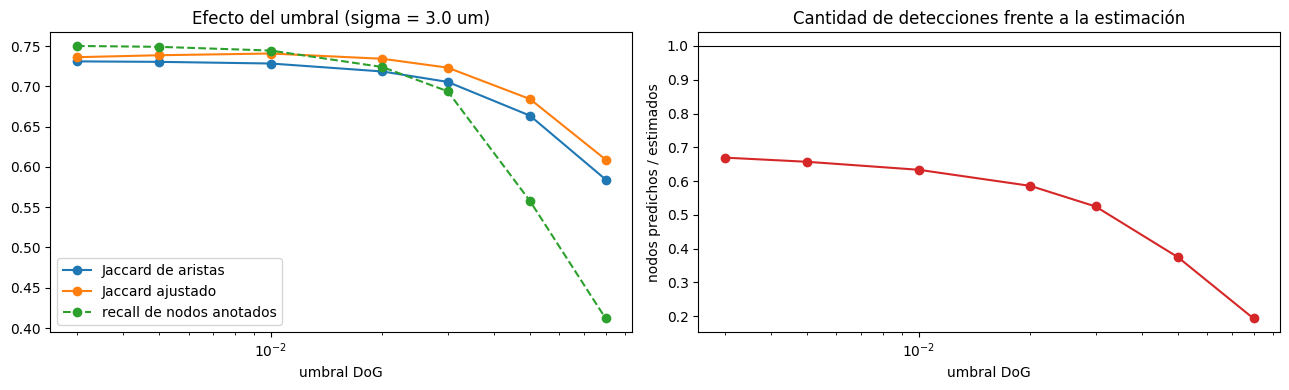

Resultado con los mejores parámetros:


,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
total,0.7408,0.7284,0.7445,0.6336,6551.0,632.0,1811.0


Por embrión:


,jaccard_ajustado,jaccard,recall_nodos,pred/estimados,tp,fp,fn
embryo_id,,,,,,,
44b6,0.5117,0.4990,0.6486,0.5903,777.0,172.0,608.0
6bba,0.7888,0.7764,0.8403,0.7708,5774.0,460.0,1203.0


In [9]:
if VALIDAR:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    t = tablas["umbral"]
    ax[0].plot(t.index, t["jaccard"], "o-", label="Jaccard de aristas")
    ax[0].plot(t.index, t["jaccard_ajustado"], "o-", label="Jaccard ajustado")
    ax[0].plot(t.index, t["recall_nodos"], "o--", label="recall de nodos anotados")
    ax[0].set_xscale("log"); ax[0].set_xlabel("umbral DoG"); ax[0].legend()
    ax[0].set_title(f"Efecto del umbral (sigma = {mejor['sigma_um']} um)")
    ax[1].plot(t.index, t["pred/estimados"], "o-", color="tab:red")
    ax[1].axhline(1, color="k", lw=.8)
    ax[1].set_xscale("log"); ax[1].set_xlabel("umbral DoG"); ax[1].set_ylabel("nodos predichos / estimados")
    ax[1].set_title("Cantidad de detecciones frente a la estimación")
    plt.tight_layout(); plt.show()

    resumen, por_muestra = evaluar(mejor)
    por_muestra["embryo_id"] = por_muestra["sample"].str.split("_").str[0]
    print("Resultado con los mejores parámetros:")
    display(resumen.round(4).to_frame("total").T)
    print("Por embrión:")
    display(por_muestra.groupby("embryo_id").apply(agregar, include_groups=False).round(4))

### Inspección visual

Proyección de máxima intensidad de un instante, con las detecciones (verde) y los núcleos anotados
(rojo). Sirve para ver qué tipo de errores comete el detector: núcleos perdidos, núcleos partidos en
dos o detecciones sobre el fondo.

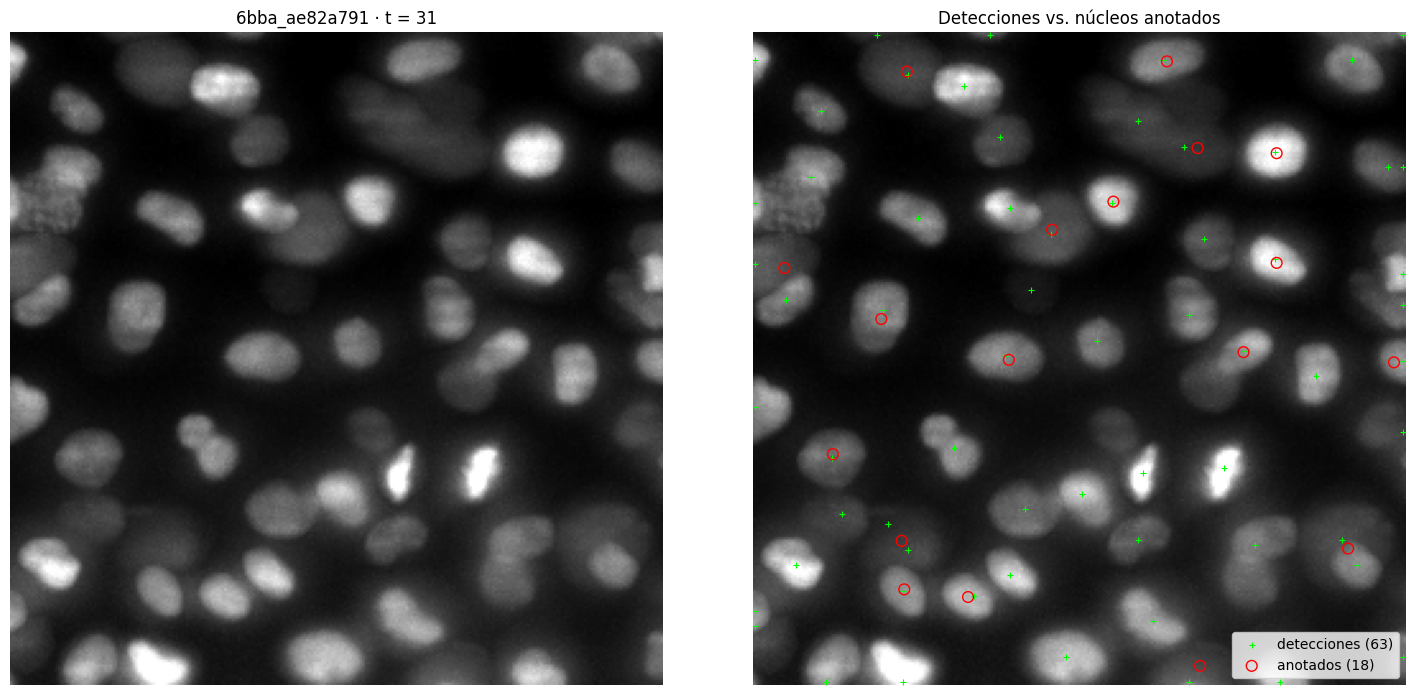

In [10]:
if VALIDAR:
    s = max(VAL, key=lambda s: len(GT[s][0]))
    gn = GT[s][0]
    t = int(gn["t"].value_counts().idxmax())
    v = ArregloZarr(TRAIN_DIR / f"{s}.zarr" / "0").instante(t)
    det_s, n_t_s, forma_s = DET[s]
    det, _ = enlazar(det_s[det_s["t"] == t], n_t_s, mejor, forma_s)
    g = gn[gn["t"] == t]
    mip = v.max(axis=0)
    fig, ax = plt.subplots(1, 2, figsize=(15, 7))
    for a in ax:
        a.imshow(mip, cmap="gray", vmin=np.percentile(mip, 1), vmax=np.percentile(mip, 99.5)); a.axis("off")
    ax[1].scatter(det["x"], det["y"], s=14, c="lime", marker="+", lw=.8, label=f"detecciones ({len(det)})")
    ax[1].scatter(g["x"], g["y"], s=60, facecolor="none", edgecolor="red", lw=1, label=f"anotados ({len(g)})")
    ax[1].legend(loc="lower right")
    ax[0].set_title(f"{s} · t = {t}"); ax[1].set_title("Detecciones vs. núcleos anotados")
    plt.tight_layout(); plt.show()

## Predicción sobre `test/` y archivo de envío

Se procesa cada muestra de prueba con `PARAMS` y se escribe `submission.csv` con el formato de la
competencia: filas de nodos (`node_id, t, z, y, x`) y filas de aristas (`source_id, target_id`), con
`-1` en los campos que no aplican. En el *rerun*, Kaggle reemplaza `test/` por el conjunto oculto, que
tiene un tamaño parecido al de `train/`.

> En una corrida interactiva se usan los mejores parámetros de la validación (`USAR_VALIDADOS`). Para
> el *rerun*, esos valores deben estar copiados en `PARAMS`.

In [11]:
USAR_VALIDADOS = True
P_FINAL = mejor if (VALIDAR and USAR_VALIDADOS) else PARAMS
print("Parámetros del envío:", P_FINAL)


def predecir(zarr_dir):
    det, n_t, forma = detectar_muestra(zarr_dir, P_FINAL, P_FINAL["umbral"])
    nodos, aristas = enlazar(det, n_t, P_FINAL, forma)
    nombre = Path(zarr_dir).name[:-5]
    filas_n = pd.DataFrame({"dataset": nombre, "row_type": "node", "node_id": nodos["node_id"],
                            "t": nodos["t"].astype(int), "z": nodos["z"].round().astype(int),
                            "y": nodos["y"].round().astype(int), "x": nodos["x"].round().astype(int),
                            "source_id": -1, "target_id": -1})
    filas_a = pd.DataFrame({"dataset": nombre, "row_type": "edge", "node_id": -1, "t": -1, "z": -1, "y": -1,
                            "x": -1, "source_id": aristas["source_id"], "target_id": aristas["target_id"]})
    return pd.concat([filas_n, filas_a], ignore_index=True)


pruebas = sorted(TEST_DIR.glob("*.zarr"))
print(f"Muestras de prueba: {len(pruebas)}")
t0 = time.time()
ruta_csv = SALIDA / "submission.csv"
ruta_csv.parent.mkdir(parents=True, exist_ok=True)
siguiente_id, primero = 0, True
LOTE = max(N_JOBS * 2, 1)
for k in range(0, len(pruebas), LOTE):
    for tabla in Parallel(n_jobs=N_JOBS)(delayed(predecir)(z) for z in pruebas[k:k + LOTE]):
        tabla.insert(0, "id", np.arange(siguiente_id, siguiente_id + len(tabla)))
        siguiente_id += len(tabla)
        tabla.to_csv(ruta_csv, mode="w" if primero else "a", header=primero, index=False)
        primero = False
    print(f"  {min(k + LOTE, len(pruebas))}/{len(pruebas)} muestras · {time.time() - t0:.0f} s", flush=True)

if primero:     # sin muestras de prueba: CSV vacío con el encabezado correcto
    pd.DataFrame(columns=["id", "dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
                 ).to_csv(ruta_csv, index=False)
print(f"\n{ruta_csv}: {siguiente_id:,} filas en {time.time() - t0:.0f} s")

Parámetros del envío: {'reduccion_xy': 2, 'sigma_um': 3.0, 'k_dog': 1.6, 'dist_min_um': 6.0, 'borde_um': 0.0, 'umbral': 0.01, 'radio_um': 8.4, 'deriva': 'dos_pasos', 'divisiones': False, 'radio_div_um': 8.0}
Muestras de prueba: 4
  4/4 muestras · 47 s

/kaggle/working/submission.csv: 168,718 filas en 47 s


In [12]:
envio = pd.read_csv(ruta_csv, nrows=200_000)
print(envio["row_type"].value_counts().to_dict())
envio.head()

{'node': 90069, 'edge': 78649}


,id,dataset,row_type,node_id,t,z,y,x,source_id,target_id
0,0,44b6_0113de3b,node,1,0,0,0,54,-1,-1
1,1,44b6_0113de3b,node,2,0,0,0,70,-1,-1
2,2,44b6_0113de3b,node,3,0,0,30,68,-1,-1
3,3,44b6_0113de3b,node,4,0,0,62,58,-1,-1
4,4,44b6_0113de3b,node,5,0,0,88,90,-1,-1
